# Ejercicio k-Nearest Neighbor

## App Reviews
En este ejercicio vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating, en función del sentimiento del comentario y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

## Importamos las librerías que vamos a utilizar

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Leemos nuestro archivo de entrada `reviews_sentiment`

Para facilitar el ejercicio, las columnas que utilizaremos serán: wordcount con la cantidad de palabras utilizadas y sentimentValue con un valor entre -4 y 4 que indica si el comentario fue valorado como positivo o negativo

Nuestras etiquetas, serán las estrellas que dieron los usuarios a la app, que son valores discretos del 1 al 5

In [10]:
reviews = pd.read_csv(r"data\reviews_sentiment.csv", sep=";")

In [12]:
reviews.describe()

,wordcount,Star Rating,sentimentValue
count,257.000000,257.000000,257.000000
mean,11.501946,3.420233,0.383849
std,13.159812,1.409531,0.897987
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.108144
50%,7.000000,3.000000,0.264091
75%,16.000000,5.000000,0.808384
max,103.000000,5.000000,3.264579


In [11]:
reviews.head()

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,Hola desde hace algo más de un mes me pone sin...,23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas...,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784


In [13]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    str    
 1   Review Text     257 non-null    str    
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    str    
 4   textSentiment   257 non-null    str    
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), str(4)
memory usage: 14.2 KB


## Rápidas visualizaciones y análisis
Al menos realiza un análisis univariante y representa la distribución del rating. Realiza otras visualizaciones para ver la relación de tus datos.

In [14]:
# ver reseñas que hay en cada puntuación (star rating)

reviews['Star Rating'].value_counts().sort_index()

Star Rating
1    37
2    24
3    78
4    30
5    88
Name: count, dtype: int64

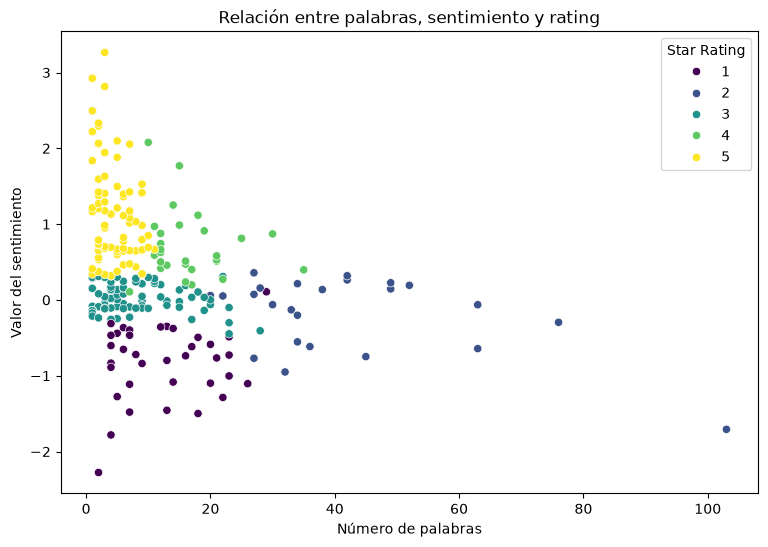

In [20]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=reviews,
    x='wordcount',
    y='sentimentValue',
    hue='Star Rating',
    palette='viridis'
)

plt.title('Relación entre palabras, sentimiento y rating')
plt.xlabel('Número de palabras')
plt.ylabel('Valor del sentimiento')
plt.show()

## Preparamos el dataset
Divide en train/test y escala las features en el rango [0, 1].

In [21]:
X = reviews[['wordcount', 'sentimentValue']]
y = reviews['Star Rating']

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# test_size=0.2: reservamos el 20 % de los datos para evaluar el modelo y el 80 % para entrenarlo.
# random_state=42: permite obtener la misma división al ejecutar el código varias veces.
# stratify=y: mantiene aproximadamente la proporción de cada puntuación (1–5 estrellas) en ambos conjuntos.

In [23]:
# escalar las variables entre 0 y 1

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
# valores del entrenamiento

pd.DataFrame(X_train_scaled, columns=X_train.columns).agg(['min', 'max'])

,wordcount,sentimentValue
min,0.0,0.0
max,1.0,1.0


## Creamos el Modelo
Entrena con un KNN y evalúa el error en train y en test

In [26]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[1,2,3,4,5]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [27]:
# predecir las estrellas tanto en los datos de entrenamiento como en los de prueba

y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

In [28]:
# evaluar el error en train y test

from sklearn.metrics import accuracy_score

accuracy_train = accuracy_score(y_train, y_train_pred)
accuracy_test = accuracy_score(y_test, y_test_pred)

error_train = 1 - accuracy_train
error_test = 1 - accuracy_test

print("Error en train:", round(error_train, 3))
print("Error en test:", round(error_test, 3))

Error en train: 0.093
Error en test: 0.096


- Error en train (0.093): el modelo se equivoca en el 9,3 % de las predicciones realizadas sobre los datos de entrenamiento.

- Error en test (0.096): el modelo se equivoca en el 9,6 % de las predicciones sobre datos nuevos.

- Diferencia entre errores: apenas 0,3 puntos porcentuales.

El modelo KNN obtiene un error del 9,3 % en entrenamiento y del 9,6 % en test, lo que equivale a una precisión del 90,7 % y 90,4 %, respectivamente.

La diferencia entre ambos errores es mínima, por lo que no se observan indicios claros de sobreajuste (overfitting).

## Evalúa tu modelo

In [30]:
# calcular accuracy

from sklearn.metrics import accuracy_score

print("Accuracy en train:", accuracy_score(y_train, y_train_pred))
print("Accuracy en test:", accuracy_score(y_test, y_test_pred))

Accuracy en train: 0.9073170731707317
Accuracy en test: 0.9038461538461539


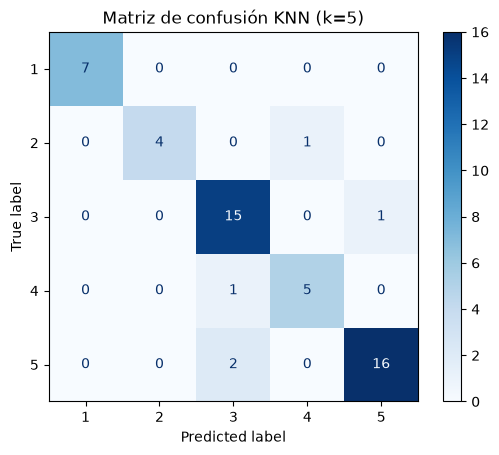

In [31]:
# matriz de confusión

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_test_pred, labels=[1, 2, 3, 4, 5])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[1, 2, 3, 4, 5]
)

disp.plot(cmap='Blues')
plt.title('Matriz de confusión KNN (k=5)')
plt.show()

In [32]:
# clasification report

from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred, zero_division=0))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         7
           2       1.00      0.80      0.89         5
           3       0.83      0.94      0.88        16
           4       0.83      0.83      0.83         6
           5       0.94      0.89      0.91        18

    accuracy                           0.90        52
   macro avg       0.92      0.89      0.90        52
weighted avg       0.91      0.90      0.90        52



## ¿Cómo obtener el mejor valor de k? Crea y evalúa nuevos modelos
¿Qué valor de k maximiza el accuracy? Representa todas las iteraciones en un scatterplot -> k vs accuracy

In [ ]:
# validación cruzada sobre los datos de entrenamiento

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

k_values = range(1, 21)
accuracy_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    accuracy_scores.append(scores.mean())

# Divide los datos de entrenamiento en 5 partes. 
# Entrena el modelo con 4 partes y lo valida con la restante, repitiendo el proceso cinco veces.
# Después se calcula la media del accuracy obtenido.
# Es una estimación más fiable para comparar distintos valores de K

In [37]:
# ver todos los valores de K y su accuracy 

for k, accuracy in zip(k_values, accuracy_scores):
    print(f"K = {k}: Accuracy = {accuracy:.4f}")

K = 1: Accuracy = 0.8244
K = 2: Accuracy = 0.8098
K = 3: Accuracy = 0.8439
K = 4: Accuracy = 0.8634
K = 5: Accuracy = 0.8488
K = 6: Accuracy = 0.8488
K = 7: Accuracy = 0.8390
K = 8: Accuracy = 0.8488
K = 9: Accuracy = 0.8293
K = 10: Accuracy = 0.8390
K = 11: Accuracy = 0.8341
K = 12: Accuracy = 0.8390
K = 13: Accuracy = 0.8146
K = 14: Accuracy = 0.8244
K = 15: Accuracy = 0.7951
K = 16: Accuracy = 0.8098
K = 17: Accuracy = 0.8000
K = 18: Accuracy = 0.8000
K = 19: Accuracy = 0.8000
K = 20: Accuracy = 0.7951


In [ ]:
# saber qué valor de K ha obtenido el mayor accuracy

best_k = list(k_values)[np.argmax(accuracy_scores)]
best_accuracy = max(accuracy_scores)

print("Mejor valor de K:", best_k)
print("Mejor accuracy medio:", round(best_accuracy, 4))

# np.argmax() devuelve la posición del valor más alto dentro de la lista de accuracies

Mejor valor de K: 4
Mejor accuracy medio: 0.8634


In [36]:
knn_best = KNeighborsClassifier(n_neighbors=best_k)

knn_best.fit(X_train_scaled, y_train)

y_pred_best = knn_best.predict(X_test_scaled)

print("Accuracy en test:", accuracy_score(y_test, y_pred_best))

Accuracy en test: 0.8846153846153846


## Predice con nuevos datos.
Ejemplo: supongamos que nos llega una review de 5 palabras y sentimiento 1

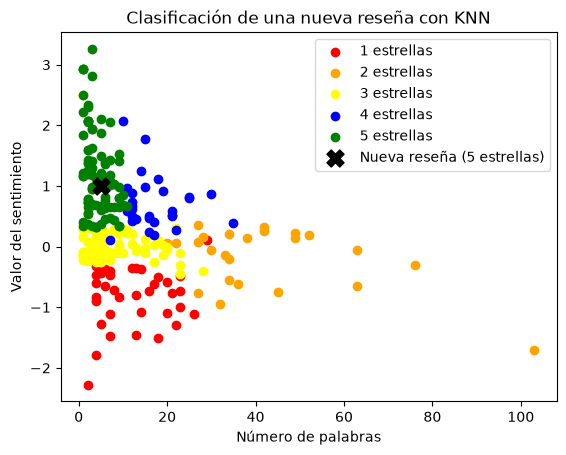

In [44]:
# Nueva reseña
punto_nuevo = {'wordcount': [5],
               'sentimentValue': [1]}

punto_nuevo = pd.DataFrame(punto_nuevo)

ax = plt.axes()

# Representar las reseñas según sus estrellas
colores = ['red', 'orange', 'yellow', 'blue', 'green']

for estrella, color in zip(range(1, 6), colores):
    ax.scatter(
        reviews.loc[reviews['Star Rating'] == estrella, 'wordcount'],
        reviews.loc[reviews['Star Rating'] == estrella, 'sentimentValue'],
        c=color,
        label=f'{estrella} estrellas'
    )

# Representar la nueva reseña
ax.scatter(
    punto_nuevo['wordcount'],
    punto_nuevo['sentimentValue'],
    c='black',
    s=150,
    marker='X',
    label='Nueva reseña (5 estrellas)'
)

plt.xlabel("Número de palabras")
plt.ylabel("Valor del sentimiento")
plt.title("Clasificación de una nueva reseña con KNN")
ax.legend()
plt.show()

In [38]:
# sabiendo que K = 4 tiene mejor accuracy, entrenar una nueva review

from sklearn.neighbors import KNeighborsClassifier

knn_best = KNeighborsClassifier(n_neighbors=4)

knn_best.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",4
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[1,2,3,4,5]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [39]:
# Crear un DataFrame con las mismas columnas que utilizamos para entrenar el modelo

nueva_review = pd.DataFrame({
    'wordcount': [5],
    'sentimentValue': [1]
})

nueva_review

,wordcount,sentimentValue
0,5,1


In [40]:
# Escalar la nueva reseña

nueva_review_scaled = scaler.transform(nueva_review)

In [46]:
from sklearn.neighbors import KNeighborsClassifier

# Crear el modelo con el mejor K
knn = KNeighborsClassifier(n_neighbors=4)

# Variables predictoras y objetivo
X = reviews[['wordcount', 'sentimentValue']]
y = reviews['Star Rating']

# Entrenar con los datos escalados
knn.fit(X_train_scaled, y_train)

# Predecir la nueva reseña (también escalada)
prediction = knn.predict(nueva_review_scaled)

print("Estrellas predichas:", prediction[0])

Estrellas predichas: 5


In [47]:
# Probar todos los K entre 1 y 5 para la nueva reseña

for k in range(1, 20):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    print('K =', k)
    print('Estrellas predichas:', knn.predict(nueva_review_scaled)[0])
    print('-' * 50)

K = 1
Estrellas predichas: 5
--------------------------------------------------
K = 2
Estrellas predichas: 5
--------------------------------------------------
K = 3
Estrellas predichas: 5
--------------------------------------------------
K = 4
Estrellas predichas: 5
--------------------------------------------------
K = 5
Estrellas predichas: 5
--------------------------------------------------
K = 6
Estrellas predichas: 5
--------------------------------------------------
K = 7
Estrellas predichas: 5
--------------------------------------------------
K = 8
Estrellas predichas: 5
--------------------------------------------------
K = 9
Estrellas predichas: 5
--------------------------------------------------
K = 10
Estrellas predichas: 5
--------------------------------------------------
K = 11
Estrellas predichas: 5
--------------------------------------------------
K = 12
Estrellas predichas: 5
--------------------------------------------------
K = 13
Estrellas predichas: 5
-------